# Paper figures

Builds every figure and table used in the paper from **saved** experiment outputs. No simulation runs here: rerun `run_mpc.ipynb` / `run_irf.ipynb` first, then run all cells. Outputs go to `data/output_data/paper-figures/`. The last cell copies the figures listed in `PAPER_FIGURES` to the paper repo `figures/` folder.

| # | Output | Files | In paper |
|---|---|---|---|
| 1a | Impact MPC by income, liquid assets, net liquid assets, borrowing, liquidity constraint | `paper_impact_mpc.png` | `fig:mpc_impact` |
| 1b | Impact MPC by balance-sheet group, split into constrained (C) and unconstrained (U) households | `paper_impact_mpc_groups.png` | `fig:mpc_groups` |
| 2 | Aggregate MPC table and cumulative MPC chart | `paper_mpc_table.*`, `paper_cumulative_mpc.png` | table only |
| 3 | MPC by the 8 balance-sheet groups, KVW robustness | `paper_mpc_by_group8.*`, `paper_mpc_by_kvw_class.csv` | no |
| 4 | IRFs: monetary tightening (one-off), one-off transfer, job loss with hiring freeze | `paper_irf_macro.png` | `fig:irf_macro` |
| 4b | Job-loss shock: household income components | `paper_job_loss_income.png` | no |
| 5 | Transfer fiscal multiplier | `paper_transfer_multiplier.*` | `fig:transfer_multiplier` |

Kept out of the paper IRF figure: the gradual monetary tightening and the income-uncertainty shock (commented in `PAPER_IRF_SHOCKS`). Excluded until fixed: income tax (payroll wedge: the tax raises CPI and consumption on impact) and government consumption (goods-market rationing crowds out household consumption).


In [43]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.household_classes import (
    GROUP_LABELS,
    HTM_CLASSES,
    classify_balance_sheet_groups,
    classify_households,
)
from src.mpc_paper_groups import prepare_paper_groups
from src.paper_plots import (
    GROUP_SHORT,
    cumulative_mpc_figure,
    irf_figure,
    mpc_characteristics_figure,
    mpc_group_constraint_figure,
    multiplier_figure,
)
from src.paper_plots import STYLE as paper_style
from src.visual_helpers import _prepare_irf_plot_panel, irf_active_quarters

MPC_DIR = Path("data/output_data/mpc-experiment/analysis")
# Which IRF run to use: "elb" (benchmark, zero floor) or "no_elb" (floor removed); see run_irf.ipynb.
IRF_REGIME = "no_elb"
# Choose the saved experiment explicitly; no simulations are launched here.
IRF_EXPERIMENT = "job_loss_designs"  # "job_loss_designs" or "legacy"
IRF_PREVENT_REHIRING = True  # For job_loss_designs: select restricted/unrestricted outputs.
IRF_REHIRING_SCOPE = "all_unemployed"  # "displaced" loads the earlier cohort-only experiment.
if IRF_EXPERIMENT not in {"job_loss_designs", "legacy"}:
    raise ValueError("IRF_EXPERIMENT must be job_loss_designs or legacy")
irf_run_name = "irf-experiment" + ("" if IRF_REGIME == "elb" else f"-{IRF_REGIME}")
if IRF_EXPERIMENT == "job_loss_designs":
    irf_run_name += "-job-loss-designs" + ("-no-rehiring" if IRF_PREVENT_REHIRING else "")
    if IRF_REHIRING_SCOPE not in {"displaced", "all_unemployed"}:
        raise ValueError("IRF_REHIRING_SCOPE must be displaced or all_unemployed")
    if IRF_PREVENT_REHIRING and IRF_REHIRING_SCOPE == "all_unemployed":
        irf_run_name += "-all-unemployed"
    JOB_LOSS_SHOCKS = {
        "unemp_1pp_once": "Separations (1% once) and four-quarter hiring freeze",
    }
else:
    JOB_LOSS_SHOCKS = {"unemp_2pp": "Job losses (legacy: 2% quarterly)"}
IRF_DIR = Path("data/output_data") / irf_run_name / "analysis"
# Income-component figure: choose one of the job-loss shocks above.
JOB_LOSS_SHOCK = next(iter(JOB_LOSS_SHOCKS))
print(f"IRF input: {IRF_DIR.resolve()}; income-chart shock: {JOB_LOSS_SHOCK}")
VAT_RATE = 0.13  # FRA household VAT in the model (central_government "Value-added Tax"); cash MPC / goods MPC = 1.13
OUT = Path("data/output_data/paper-figures")
# Paper repo figures folder: the last cell copies the figures below (prefix "paper_" dropped).
PAPER_FIG_DIR = Path("../../consumption_micro_macro_paper/figures")
# Figures included in main_conference.tex. Add a name here to copy another figure.
PAPER_FIGURES = ["impact_mpc", "impact_mpc_groups", "irf_macro", "transfer_multiplier"]
OUT.mkdir(parents=True, exist_ok=True)
# Remove figures from earlier runs, so every figure copied to the paper is regenerated below.
for old_png in OUT.glob("paper_*.png"):
    old_png.unlink()
SHOW_TRANSFER_WEIGHTED_MEAN = False  # equals the household mean: transfers are equal within a seed

# MPC measure used in every paper figure and table.
# Cash MPC = change in household cash consumption spending, i.e. goods INCLUDING VAT (+ cash rent,
# unchanged on impact), deflated by CPI, per unit of real transfer. The transfer is cash, so the
# numerator must be cash too. The VAT-exclusive goods measure (real_mpc_impact) is lower by the
# factor 1/(1+VAT) = 1/1.13: a household spending the whole transfer on goods would show 0.885.
MPC_IMPACT = "cash_real_mpc_impact"
MPC_CUMULATIVE = {
    "2 quarters": "cash_real_cmpc_2p",
    "3 quarters": "cash_real_cmpc_3p",
    "4 quarters": "cash_real_cmpc_4q",
}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
IRF input: /Users/andone/Documents/python_projects/INET-consumption/run_model/data/output_data/irf-experiment-no_elb-job-loss-designs-no-rehiring-all-unemployed/analysis; income-chart shock: unemp_1pp_once


## 0. Load the MPC panel and classify households
Groups are measured in the **baseline run (no transfer) in the transfer quarter, before the transfer is paid** (`pre_shock_row`). Income and asset quintiles pool all seeds; the 8 balance-sheet groups split at the within-seed median of NLA/y, IFA/y and HA/y (High = strictly above), as in the calibration notebook and Table `tab:household_groups`. NLA = liquid financial assets − all debt.

In [44]:
panel_path = MPC_DIR / "household_mpc_panel_filtered.csv"
if not panel_path.exists():
    panel_path = MPC_DIR / "household_mpc_panel.csv"
mpc_panel = pd.read_csv(panel_path)
mpc_panel = mpc_panel.join(classify_balance_sheet_groups(mpc_panel)[["group_code", "group_label"]])
mpc_panel, specs = prepare_paper_groups(mpc_panel)
spec = {column: (column, title, order) for column, title, order in specs}
print(f"{len(mpc_panel):,} household-seed observations, {mpc_panel.seed.nunique()} seeds")

225,288 household-seed observations, 49 seeds


## 1. Impact MPC
**Measure: cash MPC** (`cash_real_mpc_impact`): real change in cash consumption spending (goods including VAT) in the transfer quarter per unit of real transfer. Whiskers, outlier visibility and axis limits are configurable in the cell below; black dots show household means.

Figure 1a (`paper_impact_mpc`): household income, liquid financial assets, net liquid assets (all debt), borrowing, consumption liquidity constraint.

Figure 1b (`paper_impact_mpc_groups`): one panel per balance-sheet group (top row low net liquid assets, bottom row high). Each panel splits the group into liquidity-constrained (solid) and unconstrained (hatched) households, using the constraint flag of the last panel of 1a, with their share of the group under each box. The hollow diamond and its value give the group mean, the share-weighted average of the two subgroup means. `width_by_share=True` makes box widths proportional to subgroup shares. Subgroups with fewer than 200 observations across seeds are not drawn.

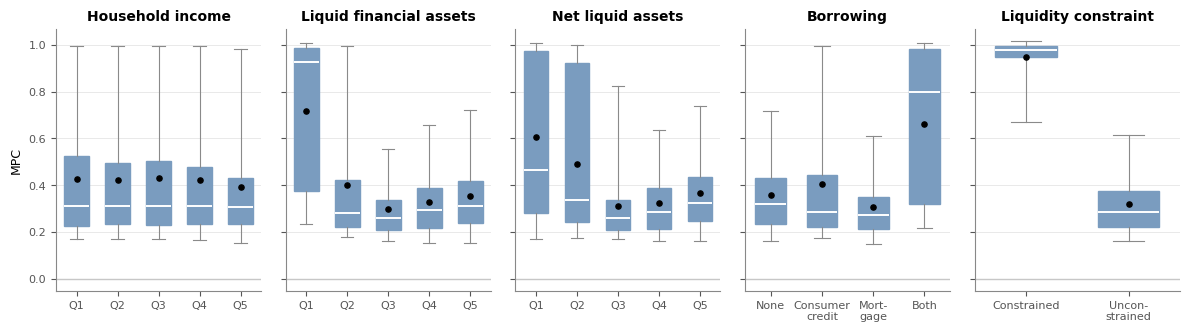

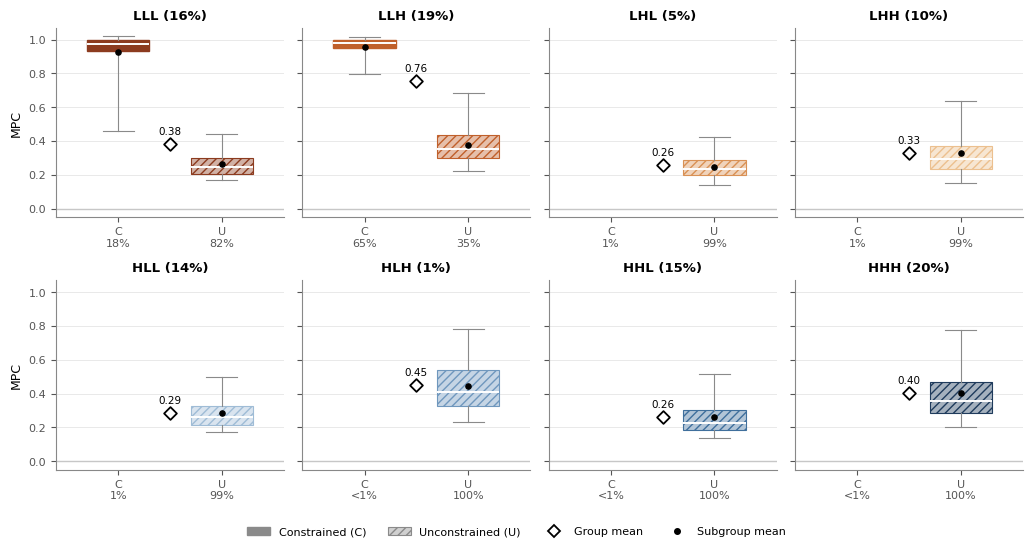

In [45]:
top_row = [
    spec["income_paper_group"][:1] + ("Household income",) + (["Q1", "Q2", "Q3", "Q4", "Q5"],),
    spec["liquid_financial_assets_paper_group"][:1] + ("Liquid financial assets",) + (["Q1", "Q2", "Q3", "Q4", "Q5"],),
    spec["net_liquid_financial_assets_all_debt_paper_group"][:1]
    + ("Net liquid assets",)
    + (["Q1", "Q2", "Q3", "Q4", "Q5"],),
    ("borrowing", "Borrowing", ["No borrowing", "Consumer\ncredit", "Mortgage\nonly", "Both"]),
    ("constraint", "Liquidity constraint", ["Constrained", "Unconstrained"]),
]
# GROUPS_TITLE = "Impact MPC by balance-sheet group and liquidity constraint"  # group-figure title
GROUPS_TITLE = None
# Display settings only: all retained observations still enter the means.
IMPACT_WHISKERS = (5, 95)  # Percentiles; (0, 100) shows min/max; 1.5 uses IQR whiskers.
IMPACT_SHOW_OUTLIERS = False  # Show individual observations beyond the whiskers.
IMPACT_YLIM = None  # Automatic limits; e.g. (-0.1, 1.3) to zoom in.
IMPACT_YLABEL = "MPC"  # y label of figure 1a
GROUPS_YLABEL = "MPC"  # y label of figure 1b: one string, or (top row, bottom row)
display = dict(outcome=MPC_IMPACT, whis=IMPACT_WHISKERS, showfliers=IMPACT_SHOW_OUTLIERS, ylim=IMPACT_YLIM)

# Figure 1a: MPC by household characteristic.
characteristic_means = mpc_characteristics_figure(
    mpc_panel, group_specs=top_row, ylabel=IMPACT_YLABEL, path=OUT / "paper_impact_mpc", **display
)
# Figure 1b: MPC by balance-sheet group, split by the same liquidity-constraint flag as the last panel of 1a.
group_means = mpc_group_constraint_figure(
    mpc_panel,
    split_column="constraint",
    title=GROUPS_TITLE,
    ylabel=GROUPS_YLABEL,
    path=OUT / "paper_impact_mpc_groups",
    **display,
)
impact_means = pd.concat([characteristic_means, group_means], ignore_index=True)
impact_means.to_csv(OUT / "paper_impact_mpc_group_means.csv", index=False)

## 2. Aggregate MPC table
Cash MPC, transfer-weighted (ΣΔC / Σtransfer) over **all** households in the filtered panel, for impact and cumulative horizons. No labour-income identification filter: cumulative MPCs include the general-equilibrium feedback of the transfer on labour income (net about +1% of the transfer). SE: standard deviation of per-seed MPCs / √seeds.

In [46]:
def weighted_mpc(panel, column):
    d = panel[np.isfinite(panel[column]) & np.isfinite(panel.real_shock_amount)]
    w = d.real_shock_amount
    per_seed = (d[column] * w).groupby(d.seed).sum() / w.groupby(d.seed).sum()
    return pd.Series(
        {
            "MPC": float((d[column] * w).sum() / w.sum()),
            "SE (seed)": float(per_seed.std(ddof=1) / np.sqrt(len(per_seed))),
            "Share < 0": float((d[column] < 0).mean()),
            "N": int(len(d)),
            "Seeds": int(d.seed.nunique()),
        }
    )


mpc_table = pd.DataFrame(
    {"Impact (transfer quarter)": weighted_mpc(mpc_panel, MPC_IMPACT)}
    | {f"Cumulative, {k}": weighted_mpc(mpc_panel, v) for k, v in MPC_CUMULATIVE.items()}
).T.astype({"N": int, "Seeds": int})
mpc_table.to_csv(OUT / "paper_mpc_table.csv")
mpc_table.style.format(
    {"MPC": "{:.3f}", "SE (seed)": "{:.4f}", "Share < 0": "{:.1%}", "N": "{:,.0f}", "Seeds": "{:.0f}"}
)

,MPC,SE (seed),Share < 0,N,Seeds
Impact (transfer quarter),0.419,0.0016,0.6%,"225,288",49
"Cumulative, 2 quarters",0.601,0.0054,4.4%,"225,288",49
"Cumulative, 3 quarters",0.800,0.0143,10.3%,"225,288",49
"Cumulative, 4 quarters",0.964,0.0191,14.8%,"225,288",49


In [47]:
latex = mpc_table[["MPC", "SE (seed)", "Share < 0", "N"]].to_latex(
    float_format="%.3f", header=["MPC", "SE (seed)", "Share $<0$", "$N$"], escape=False
)
(OUT / "paper_mpc_table.tex").write_text(latex)
print(latex)

\begin{tabular}{lrrrr}
\toprule
 & MPC & SE (seed) & Share $<0$ & $N$ \\
\midrule
Impact (transfer quarter) & 0.419 & 0.002 & 0.006 & 225288 \\
Cumulative, 2 quarters & 0.601 & 0.005 & 0.044 & 225288 \\
Cumulative, 3 quarters & 0.800 & 0.014 & 0.103 & 225288 \\
Cumulative, 4 quarters & 0.964 & 0.019 & 0.148 & 225288 \\
\bottomrule
\end{tabular}



### Cumulative MPC chart

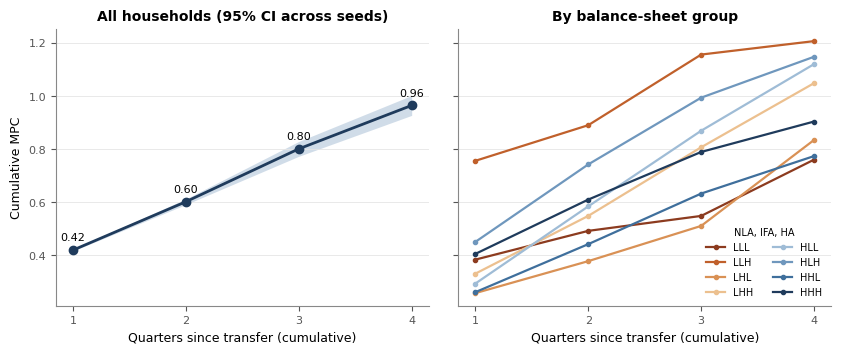

,LLL,LLH,LHL,LHH,HLL,HLH,HHL,HHH
1,0.383,0.755,0.257,0.330,0.293,0.450,0.261,0.405
2,0.491,0.889,0.377,0.548,0.584,0.742,0.441,0.609
3,0.548,1.155,0.510,0.806,0.868,0.993,0.632,0.788
4,0.760,1.206,0.834,1.047,1.119,1.147,0.773,0.903


In [48]:
horizons = {
    1: MPC_IMPACT,
    2: MPC_CUMULATIVE["2 quarters"],
    3: MPC_CUMULATIVE["3 quarters"],
    4: MPC_CUMULATIVE["4 quarters"],
}
aggregate = pd.DataFrame({q: weighted_mpc(mpc_panel, col)[["MPC", "SE (seed)"]] for q, col in horizons.items()}).T
aggregate.columns = ["MPC", "SE"]
by_group = pd.DataFrame(
    {
        code: {q: weighted_mpc(mpc_panel[mpc_panel.group_code == code], col)["MPC"] for q, col in horizons.items()}
        for code in GROUP_SHORT
    }
)
CUMULATIVE_YLABEL = "Cumulative MPC"  # y label of the cumulative MPC chart
cumulative_mpc_figure(aggregate, by_group, ylabel=CUMULATIVE_YLABEL, path=OUT / "paper_cumulative_mpc")
by_group.round(3)

## 3. MPC by balance-sheet group (table)
All eight groups. KVW (2014) classes follow as a robustness check (monthly pay, one-month credit-limit proxy, DW = top two quintiles).

In [49]:
fmt = {"Population share": "{:.1%}", "MPC": "{:.3f}", "SE (seed)": "{:.4f}", "Share < 0": "{:.1%}", "N": "{:,.0f}"}


def group_table(panel, column, order):
    rows = {
        g: weighted_mpc(panel[panel[column] == g], MPC_IMPACT).to_dict()
        | {"Population share": float((panel[column] == g).mean())}
        for g in order
    }
    return pd.DataFrame(rows).T[["Population share", "MPC", "SE (seed)", "Share < 0", "N"]].astype({"N": int})


eight_table = group_table(mpc_panel, "group_code", list(GROUP_LABELS))
eight_table.to_csv(OUT / "paper_mpc_by_group8.csv")
(OUT / "paper_mpc_by_group8.tex").write_text(eight_table.to_latex(float_format="%.3f", escape=False))
eight_table.style.format(fmt)

,Population share,MPC,SE (seed),Share < 0,N
LLL,16.4%,0.383,0.0025,0.3%,"36,923"
LLH,19.5%,0.755,0.0027,0.6%,"43,860"
LHL,4.6%,0.257,0.0021,0.8%,"10,297"
LHH,9.6%,0.330,0.0022,1.0%,"21,577"
HLL,14.1%,0.293,0.0017,0.4%,"31,839"
HLH,1.4%,0.450,0.0051,0.4%,"3,132"
HHL,14.9%,0.261,0.0017,0.8%,"33,598"
HHH,19.6%,0.405,0.0019,0.5%,"44,062"


In [50]:
# 3c. Robustness: KVW classes (monthly pay, one-month credit-limit proxy, DW = top two quintiles).
mpc_panel["htm_class"] = classify_households(mpc_panel)
kvw_table = group_table(mpc_panel, "htm_class", HTM_CLASSES)
kvw_table.to_csv(OUT / "paper_mpc_by_kvw_class.csv")
kvw_table.style.format(fmt)

,Population share,MPC,SE (seed),Share < 0,N
P-HtM,23.4%,0.287,0.0017,0.3%,"52,618"
R-HtM,35.3%,0.602,0.0023,0.7%,"79,546"
DW,23.7%,0.388,0.0020,0.6%,"53,374"
Other,17.6%,0.269,0.0015,0.7%,"39,750"


## 4. Impulse responses
Line = mean across seeds. Dark band = 25th–75th percentile and light band = 10th–90th percentile across seeds. Grey band = quarters with the shock or, for job losses, the hiring freeze active. All responses are deviations from the paired no-shock run. Units are % for real GDP, real consumption and CPI, and pp for unemployment. The policy rate is in pp, annualised (the model stores a quarterly rate). The last column is the change in income uncertainty: the household mean of the quarterly change in the uncertainty proxy θ, in units of 10⁻⁴ of the index (positive = more uncertainty). Zero lines are aligned within each row.

Monetary tightening: one +1pp p.a. innovation to the Taylor rule. The rate rises 1pp on impact and decays through smoothing (ρ = 0.904, half-life about 7 quarters). A gradual variant (four +0.29pp innovations, peak 1pp at h = 3) is in `run_irf.ipynb` as a robustness check.

Job losses: one-off separations equal to 1% of the labour force, plus a four-quarter hiring freeze for all unemployed. Unemployment therefore rises by about 8pp by the end of the freeze, far above the 1% separations.

Rows in the paper figure: one-off monetary tightening, one-off transfer, job loss with hiring freeze. The gradual monetary tightening and the income-uncertainty shock are kept as commented entries in `PAPER_IRF_SHOCKS`.

Responses still moving at h = 16 (job-loss CPI and policy rate, transfer GDP) are provisional: the model has no fiscal closure rule yet.

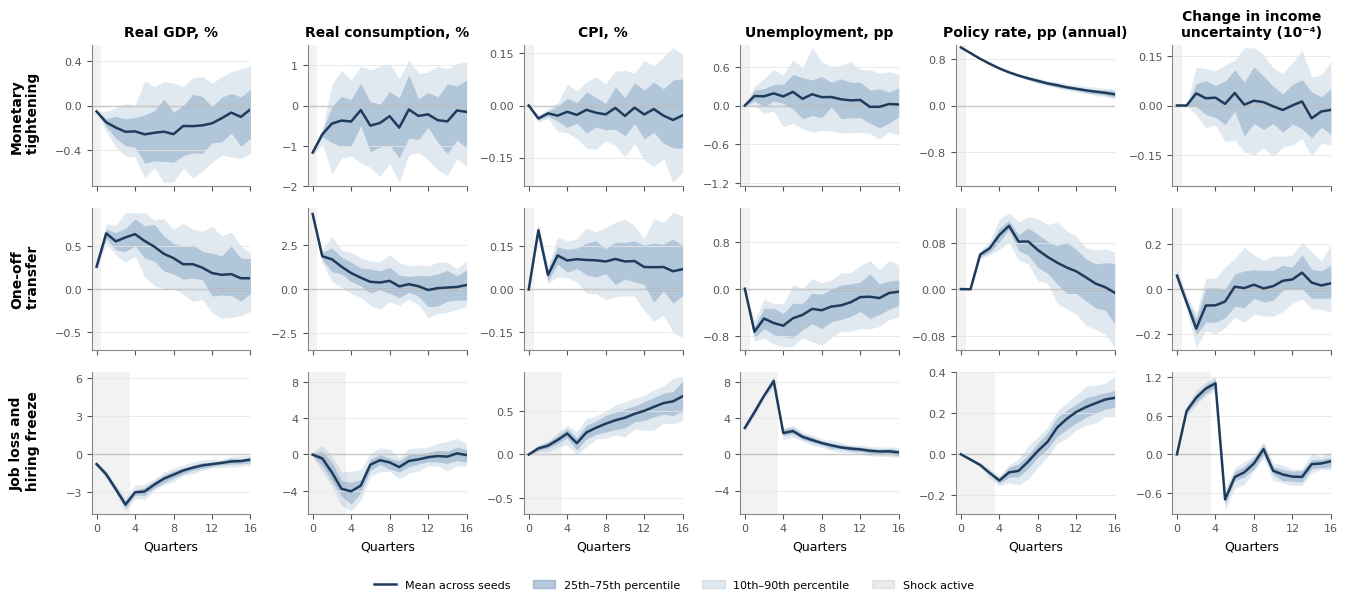

seeds per cell: [49]


In [51]:
PAPER_IRF_SHOCKS = {
    "policy_rate_1pp_once": "Monetary\n tightening",
    # "policy_rate_gradual_1pp": "Monetary\n tightening (gradual)",  # robustness only, see run_irf.ipynb
    "household_transfer_10pct": "One-off\n transfer",
    # "gov_cons_5pct": "Government\nspending shock",  # excluded: goods-market rationing crowds out consumption
    "unemp_1pp_once": "Job loss and\n hiring freeze",
    # "income_tax_5pp": "Income tax",  # excluded: payroll wedge (tax raises CPI and consumption on impact)
    # "total_income_uncertainty_1pct": "Income\nuncertainty",  # not in the paper figure
    # **JOB_LOSS_SHOCKS,
}
PAPER_IRF_VARIABLES = {
    "real_gdp": "Real GDP, %",
    "real_cons": "Real consumption, %",
    "cpi": "CPI, %",
    "unemp": "Unemployment, pp",
    "policy_rate": "Policy rate, pp (annual)",
    "income_uncertainty_delta": "Change in income\nuncertainty (10⁻⁴)",  # household mean of the quarterly change in theta
}
MAX_HORIZON = 16

irf_panel_path = IRF_DIR / "irf_panel.csv"
if not irf_panel_path.exists():
    raise FileNotFoundError(f"No saved IRFs at {irf_panel_path.resolve()}; check the experiment selectors above.")
irf_raw = pd.read_csv(irf_panel_path)
missing_shocks = set(PAPER_IRF_SHOCKS) - set(irf_raw.shock_name.unique())
if missing_shocks:
    raise ValueError(f"Selected dataset {IRF_DIR} is missing shocks: {sorted(missing_shocks)}")
irf_raw = irf_raw[irf_raw.shock_name.isin(PAPER_IRF_SHOCKS)]
irf = _prepare_irf_plot_panel(irf_raw)  # annualises interest rates (stored per quarter)
# The change in income uncertainty is a small index change: plot it in units of 1e-4.
irf.loc[irf.variable == "income_uncertainty_delta", "plot_value"] *= 1e4
irf = irf[irf.variable.isin(PAPER_IRF_VARIABLES) & (irf.horizon <= MAX_HORIZON)]
bands = (
    irf.groupby(["shock_name", "variable", "horizon"])["plot_value"]
    .agg(
        mean="mean",
        p10=lambda x: x.quantile(0.1),
        p25=lambda x: x.quantile(0.25),
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.9),
        n="count",
    )
    .reset_index()
)
bands.to_csv(OUT / "paper_irf_bands.csv", index=False)
# Quarters with the shock or the hiring freeze active, from the saved shock specification (shaded grey).
shock_durations = irf_active_quarters(pd.read_csv(IRF_DIR / "irf_shock_specs.csv"))
irf_figure(
    bands,
    shocks=PAPER_IRF_SHOCKS,
    variables=PAPER_IRF_VARIABLES,
    path=OUT / "paper_irf_macro",
    shock_durations=shock_durations,
)
print("seeds per cell:", bands.n.unique())

In [52]:
# Peak responses for the text.
peaks = bands.loc[bands.groupby(["shock_name", "variable"])["mean"].apply(lambda s: s.abs().idxmax())]
peaks[["shock_name", "variable", "horizon", "mean", "p10", "p90"]].round(3)

,shock_name,variable,horizon,mean,p10,p90
1,household_transfer_10pct,cpi,1,0.205,0.179,0.227
19,household_transfer_10pct,income_uncertainty_delta,2,-0.177,-0.259,-0.106
39,household_transfer_10pct,policy_rate,5,0.109,0.080,0.131
51,household_transfer_10pct,real_cons,0,4.307,4.166,4.409
69,household_transfer_10pct,real_gdp,1,0.654,0.537,0.763
86,household_transfer_10pct,unemp,1,-0.724,-0.883,-0.534
117,policy_rate_1pp_once,cpi,15,-0.042,-0.222,0.167
133,policy_rate_1pp_once,income_uncertainty_delta,14,-0.039,-0.153,0.086
136,policy_rate_1pp_once,policy_rate,0,1.000,1.000,1.000
153,policy_rate_1pp_once,real_cons,0,-1.171,-1.236,-1.106


### Job-loss shock: who pays for the lost wages?
Real changes (each run deflated by its own CPI) in household income components, in % of baseline household income, so the parts add up. In nominal terms transfers keep rising because they are indexed to prices and wages and the job-loss shock raises CPI. On impact the wage bill falls far less than employment (−0.9% against −3.2%): remaining workers raise effort and are paid for it (ContractWageSetter, earnings = rate × effort), so total household income rises slightly at first. This is a known limitation (work-effort response), which is why the chart is not in the paper.

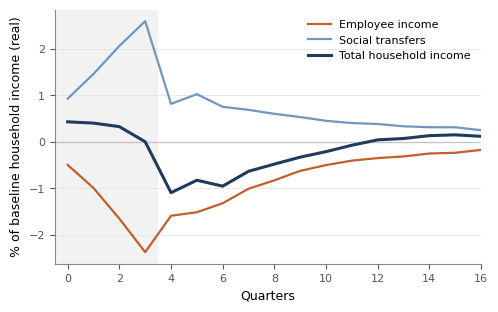

In [53]:
components = {
    "household_employee_income": "Employee income",
    "household_social_transfers": "Social transfers",
    "household_income": "Total household income",
}
if JOB_LOSS_SHOCK not in JOB_LOSS_SHOCKS:
    raise ValueError(f"Choose JOB_LOSS_SHOCK from {list(JOB_LOSS_SHOCKS)}")
raw_all = pd.read_csv(IRF_DIR / "irf_panel.csv")
job = raw_all[(raw_all.shock_name == JOB_LOSS_SHOCK) & (raw_all.horizon <= MAX_HORIZON)]
if not set(components).issubset(job.variable.unique()):
    raise ValueError(f"Missing income components for {JOB_LOSS_SHOCK} in {IRF_DIR}; check the selected saved run.")
else:
    # Real terms: deflate each run by its own CPI, in baseline prices of the same quarter.
    wide = job.pivot_table(index=["seed", "horizon"], columns="variable", values=["baseline", "shock"])
    deflator = wide["baseline", "cpi"] / wide["shock", "cpi"]
    base_income = wide["baseline", "household_income"]
    parts = (
        pd.DataFrame(
            {var: 100 * (wide["shock", var] * deflator - wide["baseline", var]) / base_income for var in components}
        )
        .groupby(level="horizon")
        .mean()
    )
    with plt.rc_context(paper_style):
        fig, ax = plt.subplots(figsize=(5.5, 3.3))
        colors = {
            "household_employee_income": "#c0602b",
            "household_social_transfers": "#6f97bd",
            "household_income": "#1f3b5c",
        }
        for var, label in components.items():
            ax.plot(
                parts.index, parts[var], label=label, color=colors[var], lw=2.2 if var == "household_income" else 1.6
            )
        # Separations or hiring freeze active; falls back to the impulse duration if the specs file lacks the shock.
        active = irf_active_quarters(pd.read_csv(IRF_DIR / "irf_shock_specs.csv"))
        duration = active.get(JOB_LOSS_SHOCK, int(job.shock_duration.iloc[0]))
        ax.axvspan(-0.5, duration - 0.5, color="#000000", alpha=0.05, lw=0, zorder=0)
        ax.axhline(0, color="#333333", lw=0.8, zorder=1)
        ax.set_xlim(parts.index.min() - 0.5, parts.index.max())
        ax.set_xlabel("Quarters")
        ax.set_ylabel("% of baseline household income (real)")
        ax.legend(fontsize=8)
        fig.savefig(OUT / "paper_job_loss_income.png", dpi=250)
        plt.show()
    parts.round(2)

## 5. Cumulative fiscal multiplier of the one-off transfer (provisional)
**Provisional:** reported to 16 quarters. The GDP multiplier is still rising at 24 quarters (deficit-financed transfer, no fiscal rule), to be resolved before final numbers.

$M_H = \sum_{h=0}^{H-1} \Delta Y^{real}_h \,/\, T$, per seed, then mean and SE across seeds.
- $T$: the transfer, measured as the h0 change in household income (labour incomes are identical across arms at h0).
- Real changes are in h0 prices: each arm is deflated by its own CPI relative to the baseline CPI at h0. No discounting.
- Consumption is in cash terms (goods including VAT, × 1.13), the same concept as the cash MPC.
- Uses the IRF run selected by `IRF_REGIME` in the setup cell.

IRF run: no_elb; transfer = 8.6% of quarterly household income; 49 seeds


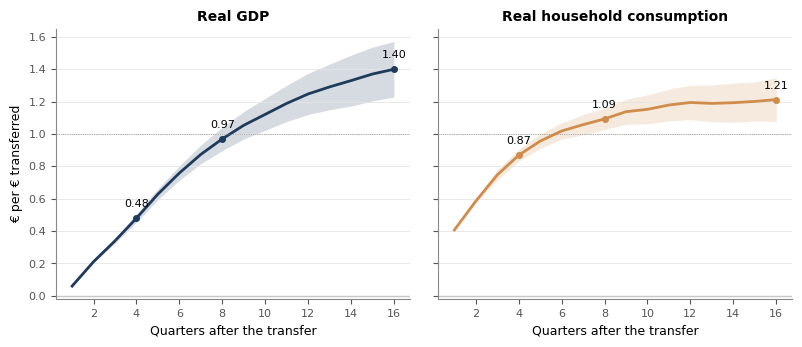

,GDP,GDP SE,Consumption,Consumption SE
Quarters,,,,
1,0.060,0.001,0.407,0.002
4,0.480,0.013,0.869,0.018
8,0.969,0.037,1.093,0.034
12,1.247,0.065,1.194,0.054
16,1.399,0.088,1.212,0.069


In [54]:
TRANSFER_SHOCK = "household_transfer_10pct"
MULTIPLIER_HORIZON = 16  # provisional: GDP multiplier has not converged by 24 quarters


def transfer_multipliers(irf_dir):
    """Per-quarter cumulative multipliers (mean and seed SE) for GDP and household consumption."""
    raw = pd.read_csv(irf_dir / "irf_panel.csv")
    raw = raw[raw.shock_name == TRANSFER_SHOCK]
    w = raw.pivot_table(index=["seed", "horizon"], columns="variable", values=["baseline", "shock", "delta"])
    cpi_b, cpi_s = w["baseline", "cpi"], w["shock", "cpi"]
    cpi_b0 = cpi_b.groupby(level=0).transform("first")
    transfer = w["delta", "household_income"].xs(0, level=1)
    out = {}
    for var, key in [("gdp_output", "gdp"), ("household_consumption", "cons")]:
        real = (w["shock", var] / (cpi_s / cpi_b0) - w["baseline", var] / (cpi_b / cpi_b0)).unstack()
        cum = real.cumsum(axis=1).div(transfer, axis=0).iloc[:, :MULTIPLIER_HORIZON]
        if key == "cons":  # IRF consumption is goods excluding VAT: express in cash terms, like the MPC
            cum = cum * (1 + VAT_RATE)
        out[key] = cum.mean()
        out[f"{key}_se"] = cum.std(ddof=1) / np.sqrt(len(cum))
    curves = pd.DataFrame(out)
    curves.index = curves.index + 1  # quarters elapsed, including the transfer quarter
    share = (transfer / w["baseline", "household_income"].xs(0, level=1)).mean()
    return curves, share, len(transfer)


curves, share, n_seeds = transfer_multipliers(IRF_DIR)
print(f"IRF run: {IRF_REGIME}; transfer = {share:.1%} of quarterly household income; {n_seeds} seeds")
MULTIPLIER_TITLES = ("Real GDP", "Real household consumption")  # edit panel titles here
multiplier_figure(
    {IRF_REGIME: curves}, path=OUT / "paper_transfer_multiplier", annotate=(4, 8, 16), titles=MULTIPLIER_TITLES
)
multiplier = curves.loc[[1, 4, 8, 12, 16]].rename(
    columns={"gdp": "GDP", "gdp_se": "GDP SE", "cons": "Consumption", "cons_se": "Consumption SE"}
)
multiplier.index.name = "Quarters"
multiplier.to_csv(OUT / "paper_transfer_multiplier.csv")
(OUT / "paper_transfer_multiplier.tex").write_text(multiplier.to_latex(float_format="%.2f"))
multiplier.round(3)

In [55]:
# Heterogeneous households in a behavioural, balance-sheet driven, agent-based model for consumption.

In [56]:
import shutil

# Copy the paper figures (PNG) into the paper repo, e.g. paper_irf_macro.png -> figures/irf_macro.png.
# Only names in PAPER_FIGURES are copied, so stale PNGs from earlier runs never reach the paper.
if not PAPER_FIG_DIR.is_dir():
    raise FileNotFoundError(f"Paper figures folder not found: {PAPER_FIG_DIR.resolve()}")
for name in PAPER_FIGURES:
    png = OUT / f"paper_{name}.png"
    if not png.exists():
        raise FileNotFoundError(f"{png} was not produced by this run; run all cells first.")
    shutil.copy2(png, PAPER_FIG_DIR / png.name.removeprefix("paper_"))
    print(f"{png.name} -> {PAPER_FIG_DIR / png.name.removeprefix('paper_')}")

paper_impact_mpc.png -> ../../consumption_micro_macro_paper/figures/impact_mpc.png
paper_impact_mpc_groups.png -> ../../consumption_micro_macro_paper/figures/impact_mpc_groups.png
paper_irf_macro.png -> ../../consumption_micro_macro_paper/figures/irf_macro.png
paper_transfer_multiplier.png -> ../../consumption_micro_macro_paper/figures/transfer_multiplier.png
